# 03 · Could the missense allele alter BUBR1?

**Place in the argument.** Track 1, mechanism. The VUS is not reclassified here; the question
is whether structure and conservation justify the functional experiment that would settle it.

**Main output.** Local geometry of the model, model confidence, and orthologous conservation.
None of it is a measurement of abundance, stability or function in the patient's cells.

> **Sanitised output.** No position and no amino-acid identity. The residue is named by its role.
>
> **Rule frozen before looking:** conservation belongs to the **mechanistic story**, not to
> classification. `PP3` had its preregistered turn with REVEL and came back indeterminate.
> Nothing in this notebook reopens it.

## The biological question

The missense is a VUS and does not move by classification. **Does it move by mechanism?**

It matters because `BUBR1` is a **pseudokinase**: catalytic activity is dispensable, and the
residues that bind ATP in conventional kinases serve **conformational stability** here. The
right question is not "does it lose catalysis?" but "is there less protein?". Published work on
other MVA alleles makes the same distinction between abundance defects and specific functional
defects ([Suijkerbuijk et al. 2010](https://doi.org/10.1158/0008-5472.CAN-09-4319)).

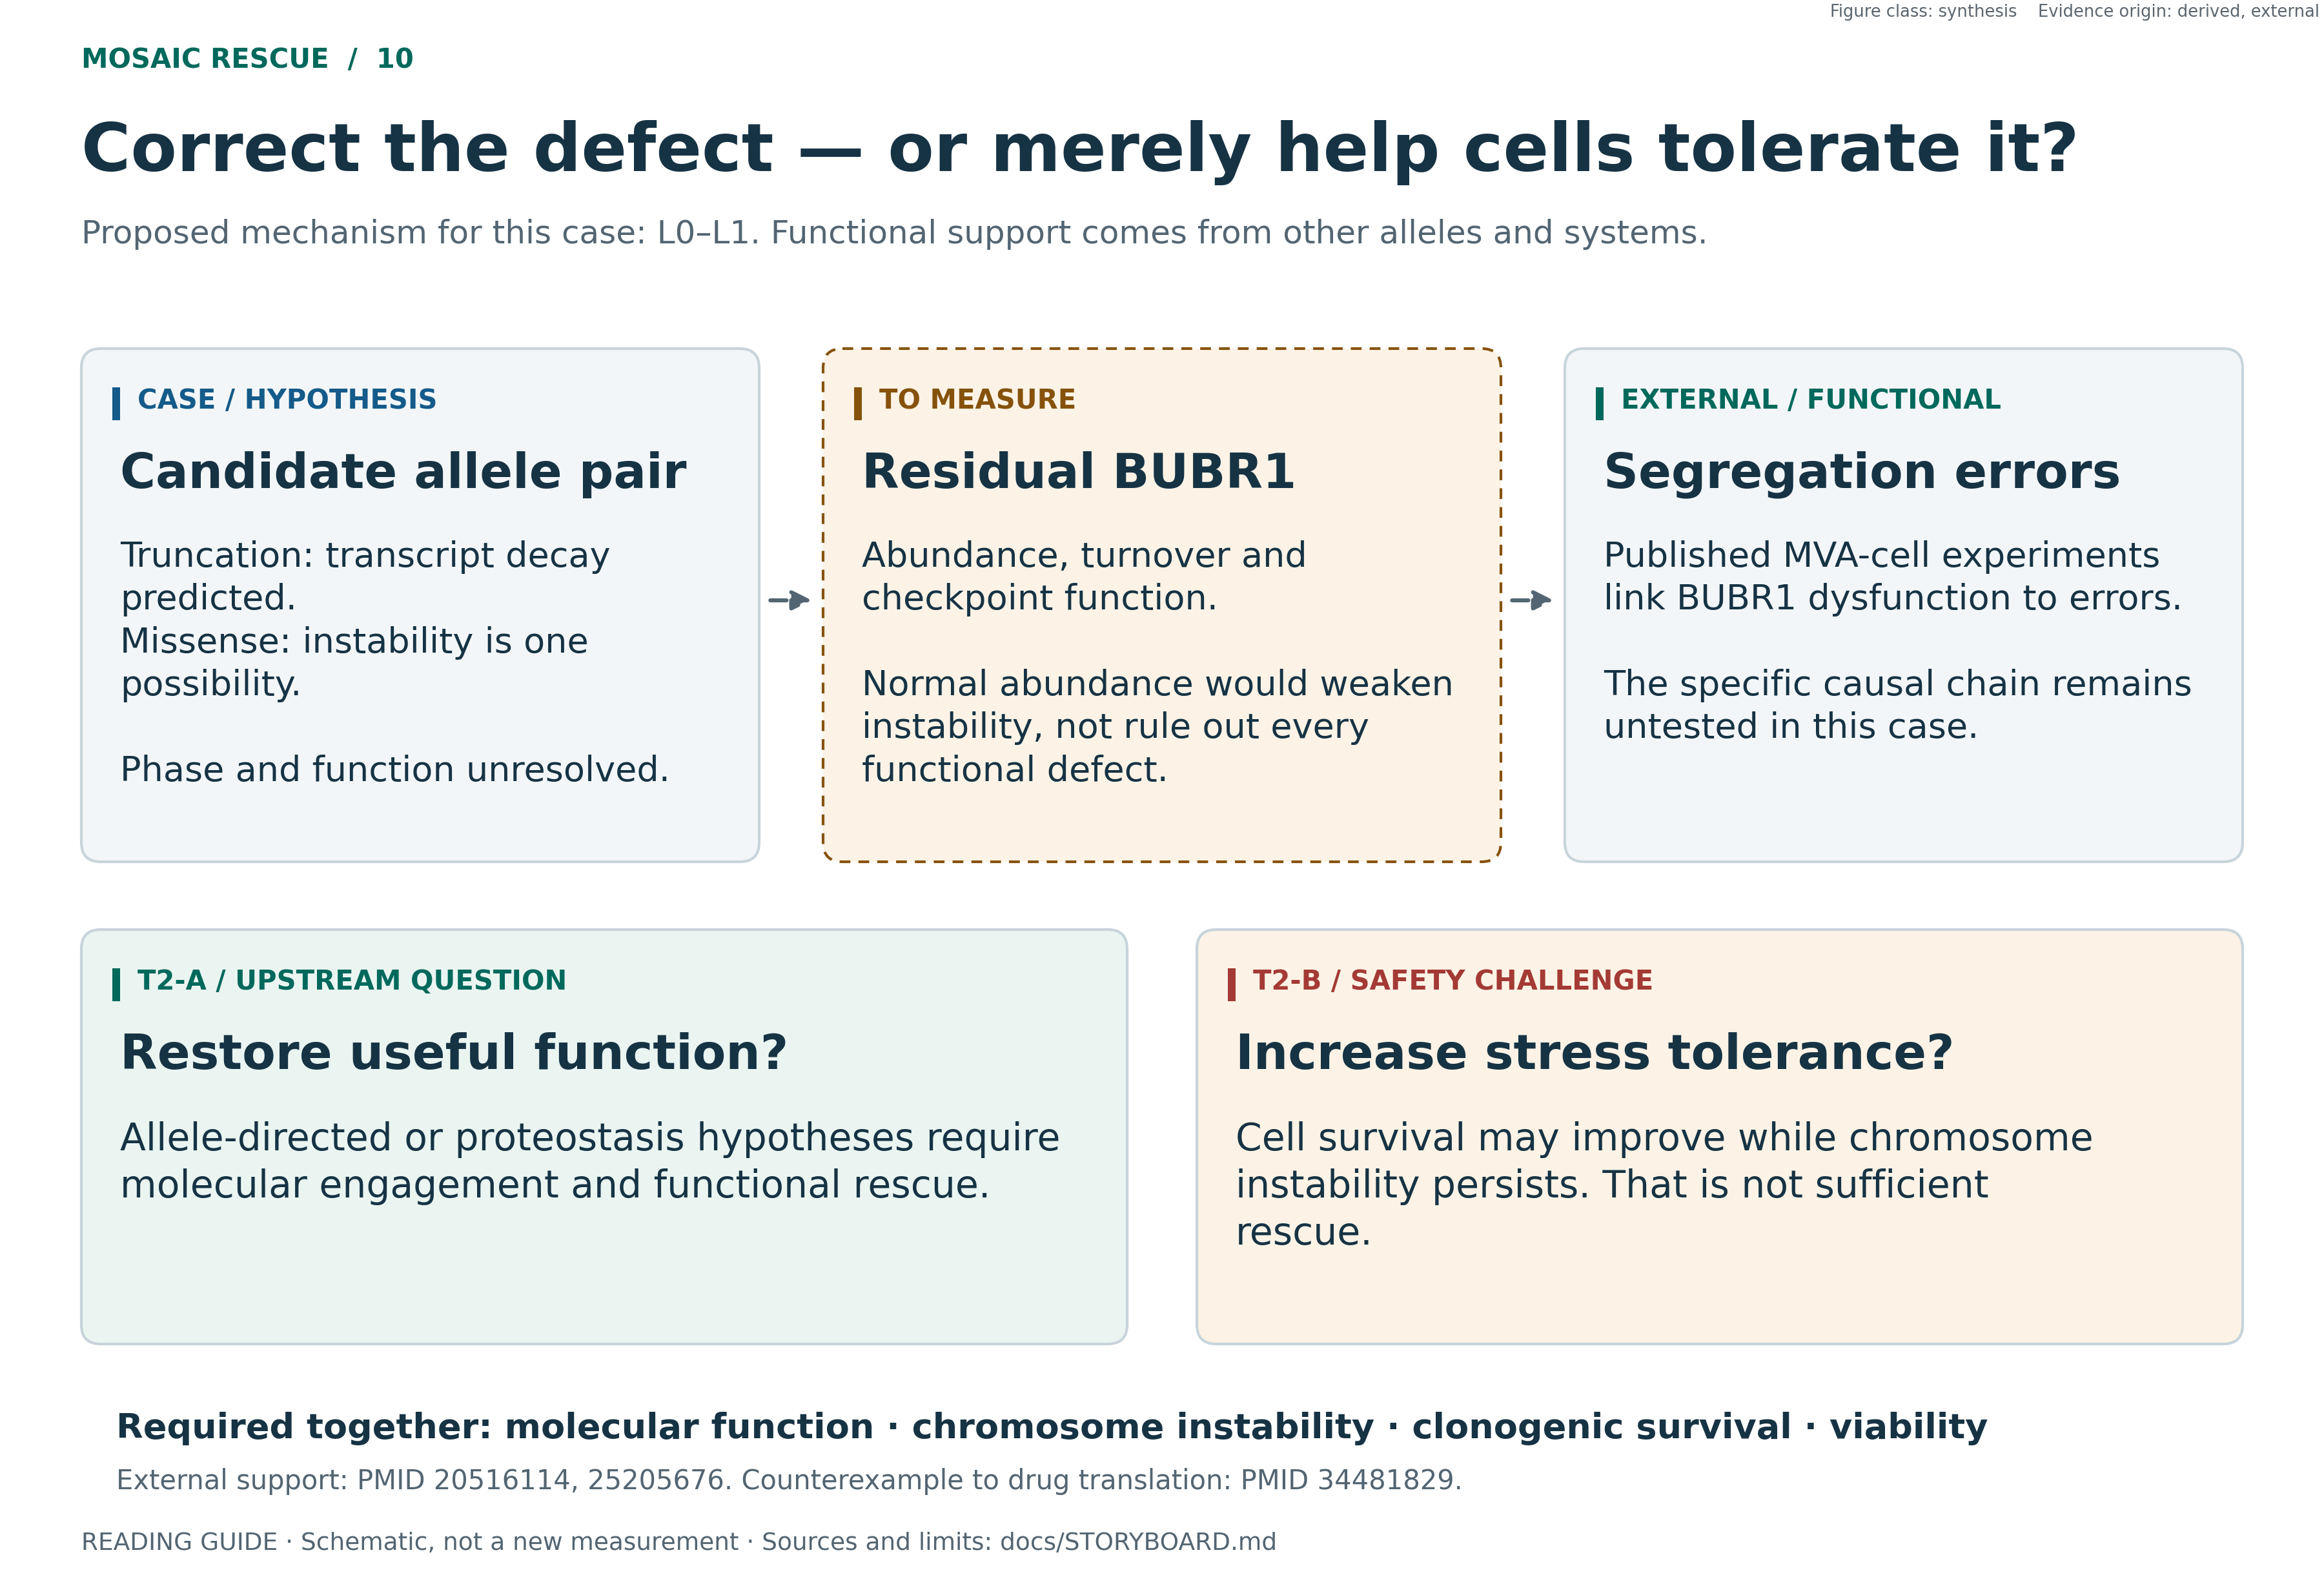

**`SYNTHESIS` · DERIVED / EXTERNAL.** A functional hypothesis; there is no protein assay and no demonstrated rescue in this case. Reviewed figure, embedded without re-running the original analysis · [sources and limits](../docs/STORYBOARD.md) · [figure QA](../PUBLICATION_FIGURE_QA.md)

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # the pipeline uses paths relative to the repo root
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # inline figures + provenance captions
print("environment ready · figures in this notebook render inline, each with a provenance caption")

environment ready · figures in this notebook render inline, each with a provenance caption


In [2]:
fl.labels("Reading", "What cannot be concluded")

## QC · is the model reliable in that region?

Without this, measuring burial or contacts would mean nothing. **Permitted use of pLDDT:** judging
whether the model is reliable there. **Forbidden use:** comparing wild-type and mutant pLDDT as
evidence of destabilisation; the brief rules it out, because ΔpLDDT correlates only weakly with
ΔΔG.

In [3]:
d = json.load(io.open("work/struct/fig4.json", encoding="utf-8"))
prof = np.array([p[1] for p in d["plddt_profile"]])
t = d["plddt_target"]
print(f"  pLDDT at the candidate residue : {t}")
print(f"  mean over the whole protein    : {prof.mean():.1f}")
print(f"  candidate percentile           : {100*(prof < t).mean():.0f}")
print(f"  relative solvent accessibility : {d['rsa']} %   (< 20 % = buried)")

  pLDDT at the candidate residue : 91.1
  mean over the whole protein    : 63.6
  candidate percentile           : 88
  relative solvent accessibility : 16.2 %   (< 20 % = buried)


## Primary result 1 · the molecule

The coordinates are read from the AlphaFold model `AF-O60566-F1`, and every distance in the
figure is computed between real heavy atoms.

> **Everything is RELATIVE to the candidate residue.** The absolute number does not appear: the
> structural argument does not need it, and printing it would be identifying.
>
> **It is a predicted model, not an experimental structure.** That is why pLDDT travels in the
> same figure: without it, an AlphaFold model reads as if it were crystallography.

In [4]:
from src.structure import pocket_geometry as pg
from src.paths import get

TGT = int(get("candidate", "residue"))
S = pg.summary(TGT)
res, NB, HB = S["res"], S["neighbours"], S["hbonds"]

def rel(n):                                   # ALWAYS relative: never the absolute number
    d = n - TGT
    return f"{d:+d}" if d else "0"

print(f"  AlphaFold model · {len(res):,} residues · candidate residue: {S['aa']} "
      f"with pLDDT {S['plddt']:.1f}")
print(f"  neighbours within {pg.CONTACT:.0f} Å of any side-chain heavy atom: {len(NB)}")
for n in NB:
    tag = "sequence-local" if n["contiguo"] else "TERTIARY contact"
    print(f"    {n['aa']}{rel(n['resnum']):<6}{n['dmin']:>5.2f} Å  "
          f"{n['atoms'][0]}-{n['atoms'][1]:<6}pLDDT {n['plddt']:>4.0f}   {tag}")
sc = [h for h in HB if h["from"] not in pg.BACKBONE]
print(f"  CANDIDATE side-chain hydrogen bonds (<= {pg.HB_MAX} Å, no angle check): {len(sc)}")
for h in sc:
    print(f"    {h['from']:<5}-> {h['to_aa']}{rel(h['to_res']):<6}{h['to_atom']:<5}"
          f"{h['dist']:>5.2f} Å")

  AlphaFold model · 1,050 residues · candidate residue: N with pLDDT 91.1
  neighbours within 5 Å of any side-chain heavy atom: 9
    W-24    2.83 Å  OD1-N     pLDDT   88   TERTIARY contact
    V-4     2.83 Å  ND2-O     pLDDT   92   sequence-local
    L-1     3.41 Å  CG-C     pLDDT   92   sequence-local
    F-25    3.46 Å  OD1-CB    pLDDT   87   TERTIARY contact
    A+1     3.78 Å  CB-N     pLDDT   88   sequence-local
    W-29    4.36 Å  OD1-CZ3   pLDDT   87   TERTIARY contact
    F-5     4.51 Å  ND2-O     pLDDT   94   TERTIARY contact
    N+2     4.62 Å  CB-ND2   pLDDT   80   sequence-local
    R-3     4.80 Å  CB-O     pLDDT   94   sequence-local
  CANDIDATE side-chain hydrogen bonds (<= 3.5 Å, no angle check): 3
    ND2  -> V-4    O     2.83 Å
    OD1  -> W-24   N     2.83 Å
    ND2  -> W-24   O     2.95 Å


### Main figure 1 · the pocket, with its real distances

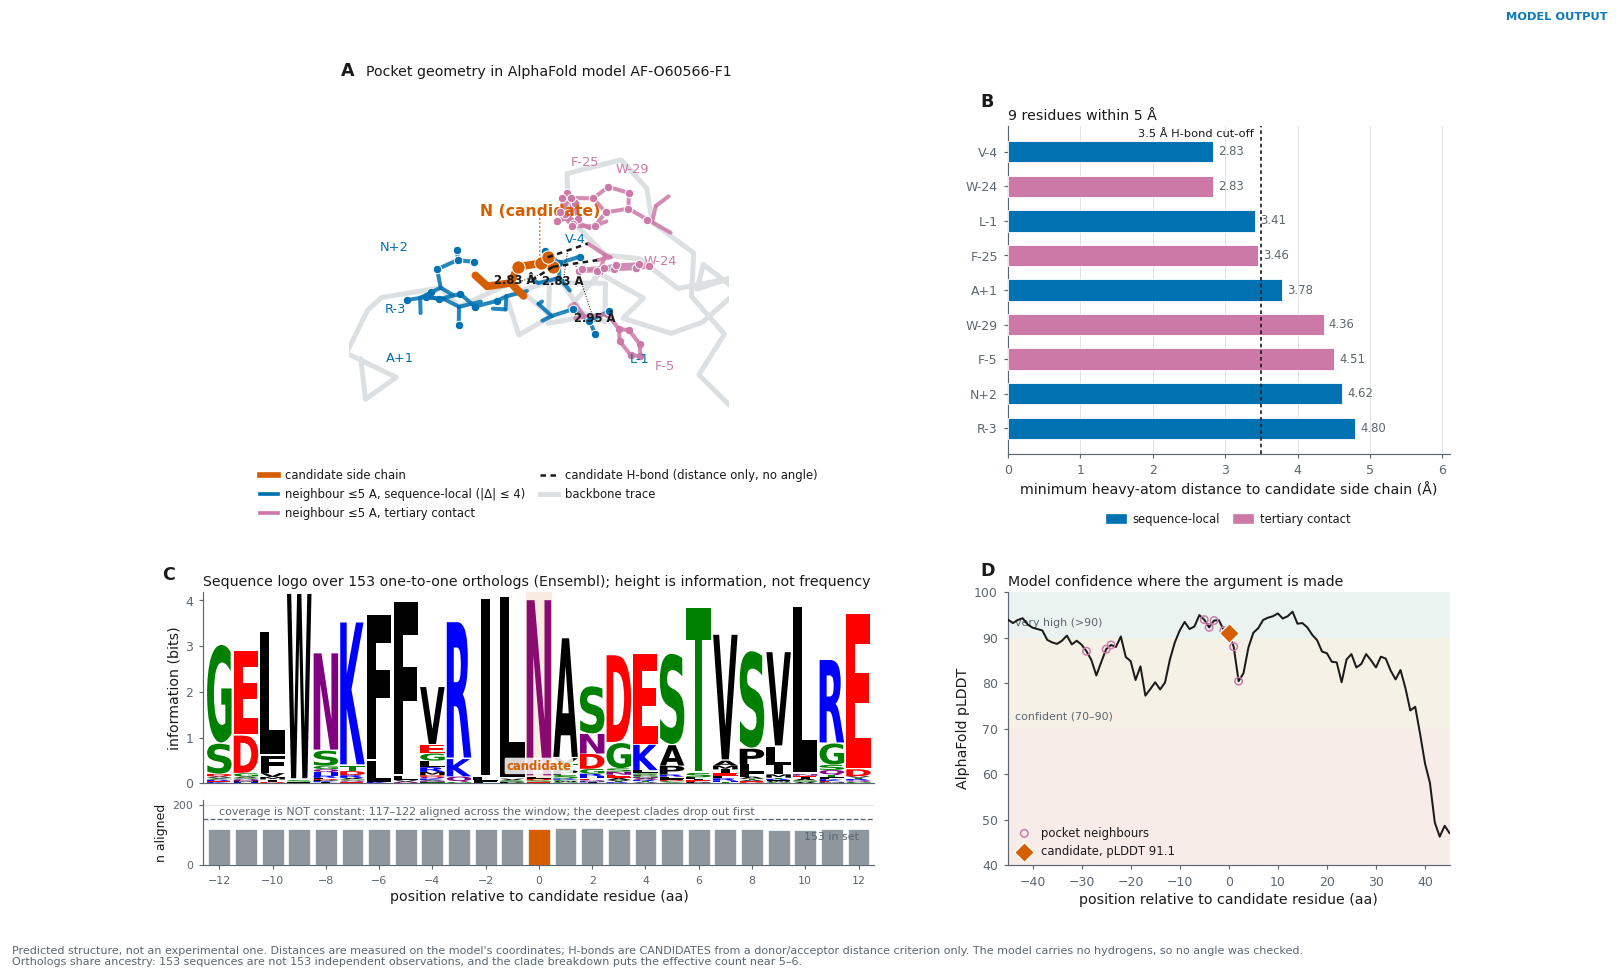

> **Main figure 1 · pocket geometry and evolutionary constraint**  
> `EXP-010 · EXP-011` · figure class `MODEL_OUTPUT`, scientific figure · evidence origin `PREDICTED+EXTERNAL`  
> *Reading.* local geometry, model confidence and evolutionary constraint in one figure. 9 residues have a heavy atom within 5 Å, of which 4 are TERTIARY contacts; 3 CANDIDATE side-chain hydrogen bonds, the shortest at 2.83 Å; pLDDT 91.1 at the candidate; and an alignment column carrying 4.04 of 4.32 bits over 153 orthologs, with alignment coverage shown because it is NOT constant.  
> **What cannot be concluded.** that the substitution destabilises the protein. It describes the WILD-TYPE residue's environment; there is no free-energy calculation, and without hydrogens in the model the hydrogen bonds are geometric candidates, not confirmed. Orthologs share ancestry: they are not independent observations, and the clade breakdown puts the effective number near 5-6.  
> data: `work/struct/AF-O60566-F1.pdb + work/conservation/orthologs.json` · library: `matplotlib 3D + logomaker + src/structure/pocket_geometry.py` · provenance: `figures/pub/fig03_pocket_and_conservation.svg + .png 300 dpi`

In [5]:
from src.figures import fig03_pocket as FP

LOGO = FP.prepare_logo(TGT)
fig = FP.build(S, LOGO)
fl.pub(fig, "Main figure 1 · pocket geometry and evolutionary constraint",
       "EXP-010 · EXP-011", "PREDICTED+EXTERNAL", "MODEL_OUTPUT",
       f"local geometry, model confidence and evolutionary constraint in one figure. "
       f"{len(NB)} residues have a heavy atom within {pg.CONTACT:.0f} Å, of which "
       f"{sum(1 for x in NB if not x['contiguo'])} are TERTIARY contacts; "
       f"{len(sc)} CANDIDATE side-chain hydrogen bonds, the shortest at "
       f"{min((h['dist'] for h in sc), default=float('nan')):.2f} Å; pLDDT {S['plddt']:.1f} at "
       f"the candidate; and an alignment column carrying {LOGO['info_at_candidate']:.2f} of "
       f"{LOGO['hmax']:.2f} bits over {LOGO['n_orthologs']} orthologs, with alignment coverage "
       f"shown because it is NOT constant.",
       "that the substitution destabilises the protein. It describes the WILD-TYPE residue's "
       "environment; there is no free-energy calculation, and without hydrogens in the model "
       "the hydrogen bonds are geometric candidates, not confirmed. Orthologs share ancestry: "
       "they are not independent observations, and the clade breakdown puts the effective "
       "number near 5-6.",
       source="work/struct/AF-O60566-F1.pdb + work/conservation/orthologs.json",
       lib="matplotlib 3D + logomaker + src/structure/pocket_geometry.py",
       slug="fig03_pocket_and_conservation")

### An interactive view of the same region, kept out of the notebook on purpose

`py3Dmol` on the **same file**. It is **not rendered here**, and the reason came from the
sanitisation scanner, not from a visual review: the widget serialises the whole PDB into the
`.ipynb`, together with `addStyle` / `zoomTo` calls carrying **absolute residue numbers**. That
would put the candidate residue into a versioned file.

So the view is generated, reproducibly, and written to `work/`, which git ignores. The scientific
figure is the static one above, which is also what GitHub displays.

In [6]:
try:
    import py3Dmol
    v = py3Dmol.view(width=900, height=520)
    v.addModel(io.open("work/struct/AF-O60566-F1.pdb", encoding="utf-8").read(), "pdb")
    v.setStyle({"cartoon": {"colorscheme": {"prop": "b", "gradient": "roygb",
                                            "min": 50, "max": 100}}})
    for nbr in NB:
        v.addStyle({"resi": nbr["resnum"]}, {"stick": {"radius": 0.14, "color": "0x8C99A4"}})
    v.addStyle({"resi": TGT}, {"stick": {"radius": 0.26, "color": "0xD55E00"}})
    v.zoomTo({"resi": [TGT] + [nbr["resnum"] for nbr in NB]})
    OUTV = "work/struct/pocket_view.html"
    io.open(OUTV, "w", encoding="utf-8").write(v.write_html())
    print(f"  interactive view written to {OUTV} ({os.path.getsize(OUTV)/1024:.0f} kB)")
    print("  cartoon coloured by pLDDT (blue high -> red low) · sticks: pocket ·")
    print("  vermilion: candidate residue · open it in a browser to rotate it")
    print()
    print("  NOT shown inline: the widget would embed the PDB and absolute residue numbers")
    print("  in the .ipynb, which is a versioned file.")
except Exception as e:
    print("py3Dmol not available in this environment:", type(e).__name__, e)

  interactive view written to work/struct/pocket_view.html (686 kB)
  cartoon coloured by pLDDT (blue high -> red low) · sticks: pocket ·
  vermilion: candidate residue · open it in a browser to rotate it

  NOT shown inline: the widget would embed the PDB and absolute residue numbers
  in the .ipynb, which is a versioned file.


## Primary result 2 · the structural interrogation, and its correction downwards

The first version concluded "destabilising". A geometric analysis of the mutant weakened two of
its three arguments (`docs/STRUCTURAL_MISSENSE.md`):

| Argument | After the mutant geometry was examined |
|---|---|
| Steric clash | **Weakened**: there is room for the incoming side chain |
| Buried charge | **Weakened**: there is solvent access nearby |
| Loss of a hydrogen bond the wild-type residue **accepts** from the backbone | **Stands**: the incoming cationic group can only donate, so no rotamer can restore it |

What survives is chemical, not geometric, in a region of high model confidence. It justifies an
explicit stability calculation and a functional assay. It does not replace either.

## Primary result 3 · orthologous conservation

A single identity percentage is uninterpretable. It needs three controls: an **internal
baseline**, **comparable coverage**, and a **clade breakdown**, because 120 orthologs are not 120
independent observations.

In [7]:
c = json.load(io.open("work/conservation/conservation_full.json", encoding="utf-8"))
cand, cc = c["candidate"], c["coverage_comparable"]
CLADE = {"primates": "primates", "otros mamiferos": "other mammals", "aves": "birds",
         "reptiles": "reptiles", "anfibios": "amphibians",
         "peces con aleta radiada": "ray-finned fish", "vertebrados basales": "basal vertebrates"}
print(f"  1:1 orthologs                          : {c['n_orthologs_one2one']}")
print(f"  identity at the candidate position     : {cand['identity_pct']} %")
print(f"  median over the whole protein          : {c['baseline']['median_identity_pct']} %")
print(f"  percentile (comparable coverage)       : {cc['candidate_percentile']}")
print(f"  hydrogen-bond ACCEPTOR capacity kept   : {cand['acceptor_pct']} %")
print()
print("  by clade:")
for r in c["by_clade"]:
    acc = f"{r['acceptor_pct']:.0f} %" if r["acceptor_pct"] is not None else "  —"
    print(f"    {CLADE.get(r['clade'], r['clade']):<20} {r['n_aligned']:>3}/{r['n_species']:<3} aligned · acceptor {acc}")

  1:1 orthologs                          : 153
  identity at the candidate position     : 96.67 %
  median over the whole protein          : 74.78 %
  percentile (comparable coverage)       : 92.7
  hydrogen-bond ACCEPTOR capacity kept   : 99.2 %

  by clade:
    primates              23/23  aligned · acceptor 100 %
    other mammals         67/68  aligned · acceptor 100 %
    birds                 12/13  aligned · acceptor 92 %
    reptiles              12/13  aligned · acceptor 100 %
    amphibians             2/2   aligned · acceptor 100 %
    ray-finned fish        4/33  aligned · acceptor 100 %
    basal vertebrates      0/1   aligned · acceptor   —


### Main figure 2 · the three controls a conservation claim needs

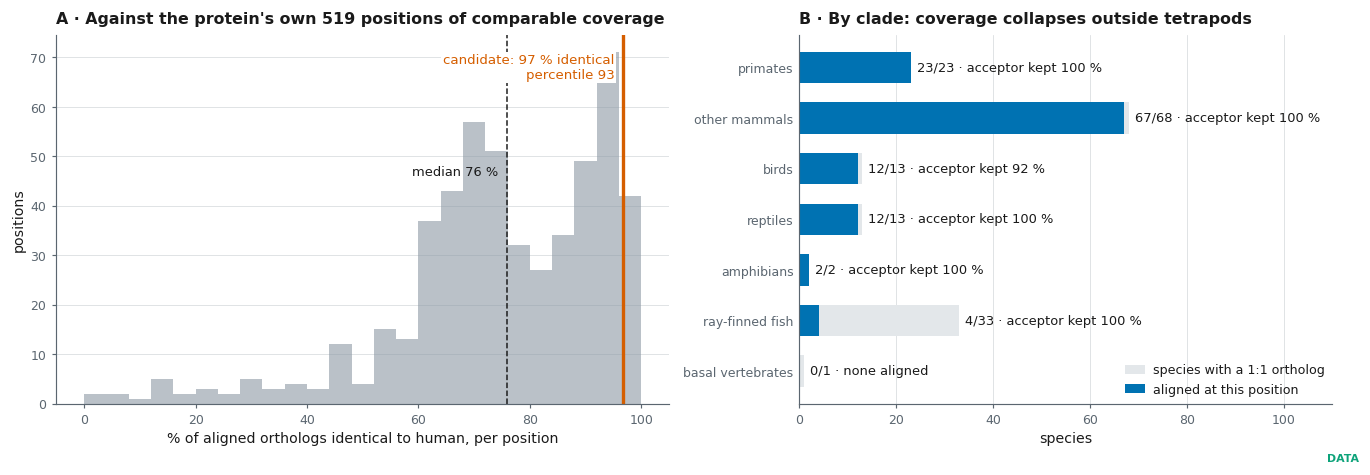

> **Main figure 2 · orthologous conservation with its three controls**  
> `EXP-011` · figure class `DATA`, scientific figure · evidence origin `EXTERNAL+DERIVED`  
> *Reading.* the position sits at percentile 92.7 of its OWN protein among positions of comparable coverage. The constraint is chemical before it is identity: 99.2 % of the aligned orthologs keep a side chain able to ACCEPT a hydrogen bond, and the cationic class introduced by the substitution appears in NONE.  
> **What cannot be concluded.** conservation across all vertebrates: only 4 of 33 ray-finned fish align and no basal vertebrate does. The effectively independent observations are ~5-6 at clade level, not 120. It says nothing about the effect of this particular substitution, and it does NOT reopen PP3.  
> data: `153 Ensembl one2one orthologs` · provenance: `work/conservation/conservation_full.json`

In [8]:
fig, (axA, axB) = plt.subplots(1, 2, figsize=(11.4, 3.9), gridspec_kw={"width_ratios": [1.15, 1]})

# A · internal baseline at comparable coverage
allp = np.asarray(cc["all_positions"], float)
axA.hist(allp, bins=np.arange(0, 101, 4), color=fl.FLOW, alpha=0.6, lw=0)
axA.axvline(cand["identity_pct"], color=fl.DEAD, lw=2)
axA.axvline(cc["median_identity_pct"], color=fl.INK, lw=0.9, ls="--")
axA.text(cand["identity_pct"] - 1.5, axA.get_ylim()[1] * 0.95,
         f"candidate: {cand['identity_pct']:.0f} % identical\npercentile {cc['candidate_percentile']:.0f}",
         ha="right", va="top", fontsize=8, color=fl.DEAD, bbox=dict(fc="white", ec="none", pad=1))
axA.text(cc["median_identity_pct"] - 1.5, axA.get_ylim()[1] * 0.62,
         f"median {cc['median_identity_pct']:.0f} %", ha="right", fontsize=7.8, color=fl.INK)
axA.set_xlabel("% of aligned orthologs identical to human, per position")
axA.set_ylabel("positions"); axA.grid(axis="y")
fl.title(axA, f"A · Against the protein's own {cc['n_positions']} positions of comparable coverage")

# B · clade breakdown: how many species align, and whether the acceptor chemistry is kept
rows_c = c["by_clade"][::-1]
y = np.arange(len(rows_c))
axB.barh(y, [r["n_species"] for r in rows_c], color="#E3E7EA", height=0.62, label="species with a 1:1 ortholog")
axB.barh(y, [r["n_aligned"] for r in rows_c], color=fl.BLUE, height=0.62, label="aligned at this position")
for yi, r in zip(y, rows_c):
    acc = f"acceptor kept {r['acceptor_pct']:.0f} %" if r["acceptor_pct"] is not None else "none aligned"
    axB.text(r["n_species"] + 1.2, yi, f"{r['n_aligned']}/{r['n_species']} · {acc}", va="center", fontsize=7.8)
axB.set_yticks(y); axB.set_yticklabels([CLADE.get(r["clade"], r["clade"]) for r in rows_c])
axB.set_xlim(0, 110); axB.set_xlabel("species"); axB.grid(axis="x")
axB.tick_params(axis="y", length=0)
axB.legend(loc="lower right", fontsize=7.6)
fl.title(axB, "B · By clade: coverage collapses outside tetrapods")

fl.done(fig, "Main figure 2 · orthologous conservation with its three controls",
        "EXP-011", "EXTERNAL+DERIVED", "DATA",
        f"the position sits at percentile {cc['candidate_percentile']} of its OWN protein among "
        f"positions of comparable coverage. The constraint is chemical before it is identity: "
        f"{cand['acceptor_pct']} % of the aligned orthologs keep a side chain able to ACCEPT a "
        "hydrogen bond, and the cationic class introduced by the substitution appears in NONE.",
        "conservation across all vertebrates: only 4 of 33 ray-finned fish align and no basal "
        "vertebrate does. The effectively independent observations are ~5-6 at clade level, not "
        "120. It says nothing about the effect of this particular substitution, and it does NOT "
        "reopen PP3.",
        prov="work/conservation/conservation_full.json",
        source=f"{c['n_orthologs_one2one']} Ensembl one2one orthologs")

### The surprise: this falsified one of the project's own explanations

`docs/STRUCTURAL_MISSENSE.md` explained the disagreement with REVEL by saying that *"a residue can
be structurally critical and still not be deeply conserved"*.

**It is conserved.** That explanation is falsified; the original text was kept with the
annotation, and **the disagreement with REVEL remains unexplained, and is more striking than
before**.

## What would move the missense, and what would not

More predictors will not move it. Only two things can: an explicit stability calculation with
convergent replicates, and above all a **variant-specific functional assay**.

## Decision

| | |
|---|---|
| **Structure** | Buried residue in a high-confidence region; rotamer-independent loss of an accepted hydrogen bond. **Structurally concerning** |
| **Conservation** | **Survives**: percentile 93, chemical constraint 99.2 %, incoming class in 0 of 120 |
| **Classification** | **Unchanged: VUS** |
| **Effect on ACMG** | **None** |

**The defensible wording:** *structurally concerning and evolutionarily constrained;
destabilisation has not been demonstrated.*

### What it does not show

It does not show destabilisation · it does not restore `PP3` · it does not establish
pathogenicity · the pocket is a conserved hydrophobic one, but **the "four-aromatic cage" is not
conserved**: one of the four is conserved neither in identity nor in class.

### Falsifier

An explicit ΔΔG close to zero with convergent replicates; or a functional ortholog carrying a
cation at that position.

### Next experiment

**A variant-specific BUBR1 abundance and turnover assay** (`EXP-011b`), with kinetochore
localisation and checkpoint arrest, wild-type and known MVA-allele controls. It is the only thing
that resolves what neither sequence nor static structure can touch. **This project does not run
it**; it is recorded because every branch must end by naming the experiment that would reduce
the uncertainty most. It is open question 2 of the
[Track 1 conclusions](../reports/TRACK1_REPORT.md).